John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

# Ablation 1: do neighbour song counts, and distance weighting, help predict the next song type?

Trimmed from `06_distance_weighted_candidate_match_window60_random_forest`. It keeps only the code needed to run **Ablation 1** and plot its results; the main model, tuning, confusion matrices, importance plots and Ablation 2 are removed.

**What it does**

1. Loads the candidate-level data (one row per event and candidate song type) and builds the same grouped 70/30 split and 5-fold CV as the original (`set.seed(42)`, split by `event_id`).
2. Tunes and tests four random forests per male on the same events and folds. All four contain the candidate song type (`candidate_ust`) and the focal male's last two song types:

| Model | Extra predictors |
|---|---|
| baseline (own history) | none |
| unweighted | `n_ust_<t>_window` (neighbour song counts, last 60 s) |
| weighted | `n_ust_<t>_last60s_wtd` (distance-weighted counts) |
| both | both sets of counts |

3. Compares them with a most-common-song baseline in a bar chart of top-1 accuracy.

**Requires** the `*_candidate_classification.csv` files in `data/by_id`, which include the distance-weighted columns produced by notebook 02.

Import Packages

In [1]:
# data.table is loaded first so that dplyr's first()/last()/between() take precedence
library(data.table)
library(tidyverse)
library(tidymodels)
library(ranger)
library(furrr)
set.seed(42)

Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'tidyverse' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'readr' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'lubridate' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.ta

Settings

In [2]:
MODEL_NAME <- "candidate_match_distance_weighted_window60"   # kept so output file names match the original notebook

CANDIDATE_DIR <- "data/by_id"
RESULTS_DIR   <- "data/2026_results"

# Own-song history lags. Notebook 21 uses lags 1 and 2 (its 3rd lag is commented out).
OWN_LAGS <- 1:2

# In notebook 21 the n_ust_*_window counts reach the model as factors
# (as.factor(across(contains("UST"))) is case-insensitive, so it also catches "n_ust_*_window").
# TRUE reproduces that; FALSE treats the counts as numeric.
WINDOW_AS_FACTOR <- TRUE

# Distance-weighted neighbour features from notebook 02 (columns ending in _wtd, plus the unweighted
# n_songs_ / n_singers_ counterparts). They are continuous, so they are kept numeric.

ADD_DIST_WEIGHTED <- TRUE

# Notebook 21 used drop_na(). In candidate data a missing feature belongs to the whole event,
# so TRUE drops every event that has an NA in any predictor (this keeps exactly one match per event).
# FALSE keeps those events and imputes in the recipe (median for numeric, "unknown" for factors).
DROP_NA_EVENTS <- TRUE

dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)

Load candidate-level data (the window and distance-weighted columns are already in the candidate files)

In [3]:
candidate_files <- list.files(CANDIDATE_DIR, pattern = "_candidate_classification\\.csv$", full.names = TRUE)
if (length(candidate_files) == 0) stop("No *_candidate_classification.csv files found in ", CANDIDATE_DIR)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

# Window columns, selected the way notebook 21 does it:
# contains("window"), minus "target" and "others" -- and minus the candidate-specific candidate_* columns.
select_window_cols <- function(col_names) {
    has_window <- str_detect(col_names, regex("window", ignore_case = TRUE))
    excluded   <- str_detect(col_names, regex("target|others", ignore_case = TRUE)) |
                  str_starts(col_names, "candidate_")
    col_names[has_window & !excluded]
}

# Distance-weighted features written by notebook 02. Their names contain no "window", so
# select_window_cols() never matches them and WINDOW_AS_FACTOR can't turn them into factors.
select_weighted_cols <- function(col_names) {
    col_names[str_detect(col_names, "_wtd$|^n_(songs|singers)_last[0-9]+s$")]
}

ID_COLS <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")

build_male_data <- function(song_data, id_value, number_value, source_name) {
    male_prefix   <- paste0("M", number_value)
    own_type_cols <- paste0(male_prefix, "_", OWN_LAGS, "_last_UST")
    own_time_cols <- paste0("time_since_", male_prefix, "_", OWN_LAGS, "_last_song")
    window_cols   <- select_window_cols(names(song_data))
    weighted_cols <- if (ADD_DIST_WEIGHTED) select_weighted_cols(names(song_data)) else character(0)

    required_columns <- c("event_id", "candidate_ust", "match", own_type_cols, own_time_cols)
    missing_columns  <- setdiff(required_columns, names(song_data))
    if (length(missing_columns) > 0) {
        stop(sprintf("Missing required columns in %s for %s: %s",
                     source_name, male_prefix, paste(missing_columns, collapse = ", ")))
    }
    if (length(window_cols) == 0) {
        stop(sprintf("No window columns found in %s. Check select_window_cols().", source_name))
    }
    if (ADD_DIST_WEIGHTED && length(weighted_cols) == 0) {
        stop(sprintf("No distance-weighted columns found in %s. Re-run notebook 02.", source_name))
    }

    # Standardised names for the own-history features
    own_type_new <- paste0("focal_last_", OWN_LAGS, "_ust")
    own_time_new <- paste0("focal_time_since_last_", OWN_LAGS)

    male_data <- song_data %>%
        filter(as.character(male_number) == number_value) %>%
        select(event_id, candidate_ust, match, all_of(window_cols), all_of(weighted_cols),
               all_of(setNames(own_type_cols, own_type_new)),
               all_of(setNames(own_time_cols, own_time_new))) %>%
        mutate(
            focal_male    = paste0(id_value, "_", male_prefix),
            focal_id      = id_value,
            male_number   = number_value,
            candidate_ust = as.factor(as.character(candidate_ust)),
            match_class   = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match")),
            across(all_of(own_type_new), ~ as.factor(as.character(.x)))
        ) %>%
        select(-match) %>%
        relocate(focal_male, focal_id, male_number, event_id, candidate_ust, match_class)

    if (WINDOW_AS_FACTOR) {
        male_data <- male_data %>% mutate(across(all_of(window_cols), as.factor))
    }

    predictor_cols  <- setdiff(names(male_data), ID_COLS)
    n_events_before <- n_distinct(male_data$event_id)

    if (DROP_NA_EVENTS) {
        na_events <- male_data %>%
            filter(if_any(all_of(predictor_cols), is.na)) %>%
            distinct(event_id)
        male_data <- male_data %>% anti_join(na_events, by = "event_id")
    }

    event_checks <- male_data %>%
        group_by(event_id) %>%
        summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (nrow(event_checks) == 0 || any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) {
        stop(sprintf("Invalid candidate events for %s_%s in %s", id_value, male_prefix, source_name))
    }

    attr(male_data, "window_cols")         <- window_cols
    attr(male_data, "predictor_cols")      <- predictor_cols
    attr(male_data, "n_events_dropped_na") <- n_events_before - n_distinct(male_data$event_id)
    male_data
}

model_data_by_male <- list_flatten(map(candidate_files, function(candidate_file) {
    song_data     <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids     <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- unique(as.character(song_data$male_number))
    focal_numbers <- focal_numbers[!is.na(focal_numbers)]
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) {
        build_male_data(song_data, focal_ids, focal_number, source_name = candidate_file)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

In [4]:
# Overview of the candidate data used for modelling
map_dfr(model_data_by_male, ~ tibble(
    focal_male          = first(.x$focal_male),
    n_events            = n_distinct(.x$event_id),
    n_events_dropped_na = attr(.x, "n_events_dropped_na"),
    n_candidate_rows    = nrow(.x),
    n_song_types        = n_distinct(.x$candidate_ust),
    n_predictors        = length(attr(.x, "predictor_cols"))
))

focal_male,n_events,n_events_dropped_na,n_candidate_rows,n_song_types,n_predictors
<chr>,<int>,<int>,<int>,<int>,<int>
DgTbO_M5,1157,10,32396,28,194
DgTbO_M6,989,10,27692,28,194
KLgK_M5,508,8,9652,19,125
KRDg_M2,1011,10,26286,26,146
LbOW_M1,689,10,12402,18,128
RbDgY_M2,650,6,13650,21,137
RRO_M6,525,10,9975,19,131
TbTbLg_M4,724,10,13756,19,131
TbWY_M1,594,10,10098,17,119


Train/test split and cross-validation (grouped by event, so all candidates of an event stay together)

In [5]:
male_splits     <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data  <- map(male_splits, testing)
male_vfolds     <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

## Ablation 1

Predictors (nothing else is used):

* **baseline** (own history): `candidate_ust` + the focal male's last two song types
* **unweighted**: baseline + `n_ust_<t>_window`
* **weighted**: baseline + `n_ust_<t>_last60s_wtd`
* **both**: baseline + both sets of counts

Left out on purpose: `n_songs_*` / `n_singers_*`, `nbr_last_*` and time-since-last-song. Each model is tuned (top-1 accuracy, grouped CV) and tested on exactly the same events, split and folds.

In [6]:
# ---- Settings ----------------------------------------------------------------
# FALSE: the unweighted counts are numeric, like the weighted ones, so the comparison
#        is not confounded by factor vs numeric coding.
# TRUE : keep them as factors, as in the main model.
WINDOW_COUNTS_AS_FACTOR <- FALSE

abl_tune_trees  <- 300
abl_final_trees <- 1000
abl_mtry_fracs  <- c(0.05, 0.10, 0.25, 0.50)   # mtry as a fraction of the number of predictors
abl_min_n_grid  <- c(5, 10, 20, 40)

abl_id_cols <- c("focal_male", "focal_id", "male_number", "event_id", "match_class")
own_cols    <- paste0("focal_last_", OWN_LAGS, "_ust")

In [7]:
# ---- Helpers -----------------------------------------------------------------
abl_feature_sets <- function(col_names) {
    unw <- str_subset(col_names, "^n_ust_[0-9]+_window$")
    wtd <- str_subset(col_names, "^n_ust_[0-9]+_last[0-9]+s_wtd$")
    if (length(unw) == 0 || length(wtd) == 0) {
        stop("Unweighted or distance-weighted song count columns not found.")
    }
    list(
        baseline   = c("candidate_ust", own_cols),
        unweighted = c("candidate_ust", unw, own_cols),
        weighted   = c("candidate_ust", wtd, own_cols),
        both       = c("candidate_ust", unw, wtd, own_cols)
    )
}

abl_prep_df <- function(df, cols) {
    df <- df %>% select(all_of(abl_id_cols), all_of(cols))
    if (!WINDOW_COUNTS_AS_FACTOR) {
        df <- df %>% mutate(across(matches("^n_ust_[0-9]+_window$"), ~ as.numeric(as.character(.x))))
    }
    df
}

# Same recipe as the main model
abl_recipe <- function(df) {
    recipe(match_class ~ ., data = df) %>%
        update_role(focal_male, focal_id, male_number, event_id, new_role = "id") %>%
        step_unknown(all_nominal_predictors()) %>%
        step_impute_median(all_numeric_predictors()) %>%
        step_zv(all_predictors())
}

abl_make_grid <- function(n_predictors) {
    tidyr::crossing(
        mtry  = unique(pmax(1L, as.integer(round(abl_mtry_fracs * n_predictors)))),
        min_n = abl_min_n_grid
    )
}

abl_spec <- function(mtry, min_n, trees, threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = "none", probability = TRUE,
                   num.threads = threads, respect.unordered.factors = "order") %>%
        set_mode("classification")
}

abl_top1 <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1, mean(match_class == "match")]
}

abl_rank_metrics <- function(pred) {
    ranks <- pred %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(rank = which(match_class == "match")[1], n_cand = n(), .groups = "drop")
    tibble(n_test_events = nrow(ranks),
           accuracy = mean(ranks$rank == 1),
           random_baseline = mean(1 / ranks$n_cand),
           top3_recall = mean(ranks$rank <= 3),
           mean_reciprocal_rank = mean(1 / ranks$rank),
           mean_rank = mean(ranks$rank))
}

# ---- One male: tune + test every feature set --------------------------------
run_ablation_one <- function(train, test, folds_idx, focal_male, threads = 1) {
    setDTthreads(1)
    map_dfr(abl_feature_sets(names(train)), .id = "feature_set", function(cols) {
        tr <- abl_prep_df(train, cols)
        te <- abl_prep_df(test, cols)
        grid <- abl_make_grid(length(cols))

        # Prep + bake each CV fold once (same folds as the main model)
        folds <- map(folds_idx, function(idx) {
            a   <- tr[idx$analysis, ]
            s   <- tr[idx$assessment, ]
            rec <- prep(abl_recipe(a))
            list(train = bake(rec, new_data = NULL, all_predictors(), all_outcomes()),
                 test  = bake(rec, new_data = s,    all_predictors(), all_outcomes()),
                 meta  = s %>% select(event_id, match_class))
        })

        tuning <- pmap_dfr(grid, function(mtry, min_n) {
            acc <- map_dbl(folds, function(f) {
                spec  <- abl_spec(min(mtry, ncol(f$train) - 1L), min_n, abl_tune_trees, threads)
                fit_i <- fit(spec, match_class ~ ., data = f$train)
                preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
                abl_top1(preds)
            })
            tibble(mtry = mtry, min_n = min_n,
                   cv_accuracy = mean(acc), cv_se = sd(acc) / sqrt(length(acc)))
        }) %>% arrange(desc(cv_accuracy), cv_se)
        best <- tuning %>% slice(1)

        # Refit on all training data, evaluate on the held-out test events
        rec  <- prep(abl_recipe(tr))
        tr_b <- bake(rec, new_data = NULL, all_predictors(), all_outcomes())
        te_b <- bake(rec, new_data = te,   all_predictors(), all_outcomes())
        spec  <- abl_spec(min(best$mtry, ncol(tr_b) - 1L), best$min_n, abl_final_trees, threads)
        fit_f <- fit(spec, match_class ~ ., data = tr_b)
        pred  <- predict(fit_f, te_b, type = "prob") %>% bind_cols(te %>% select(event_id, match_class))

        bind_cols(tibble(focal_male = focal_male, n_predictors = length(cols)),
                  best %>% select(mtry, min_n, cv_accuracy),
                  abl_rank_metrics(pred))
    })
}

Run in parallel across males, then summarise

In [8]:
# ---- Run in parallel across males --------------------------------------------
# Row indices of each CV fold, so the folds can be re-applied to the column subsets
fold_idx <- map(male_vfolds, function(v) {
    map(v$splits, function(s) {
        list(analysis   = s$in_id,
             assessment = setdiff(seq_len(nrow(s$data)), s$in_id))
    })
})

plan(multisession, workers = max(1, parallel::detectCores() - 1))

ablation_results <- future_pmap_dfr(
    list(male_train_data, male_test_data, fold_idx, names(male_train_data)),
    run_ablation_one,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble", "tidyr", "stringr"),
        globals = c("abl_id_cols", "own_cols", "abl_feature_sets", "abl_prep_df", "abl_recipe",
                    "abl_make_grid", "abl_spec", "abl_top1", "abl_rank_metrics",
                    "abl_tune_trees", "abl_final_trees", "abl_mtry_fracs", "abl_min_n_grid",
                    "WINDOW_COUNTS_AS_FACTOR")
    )
)

plan(sequential)

# ---- Results -----------------------------------------------------------------
feature_levels <- c("baseline", "unweighted", "weighted", "both")
ablation_results <- ablation_results %>%
    mutate(feature_set = factor(feature_set, levels = feature_levels))

write_csv(ablation_results, file.path(RESULTS_DIR, paste0(MODEL_NAME, "_ablation.csv")))

# 1. Averages across males
ablation_summary <- ablation_results %>%
    group_by(feature_set) %>%
    summarise(mean_predictors = mean(n_predictors),
              accuracy = mean(accuracy),
              random_baseline = mean(random_baseline),
              top3_recall = mean(top3_recall),
              mean_reciprocal_rank = mean(mean_reciprocal_rank),
              mean_rank = mean(mean_rank),
              .groups = "drop")
print(ablation_summary)

# 2. Top-1 accuracy per male
acc_wide <- ablation_results %>%
    select(focal_male, feature_set, accuracy) %>%
    pivot_wider(names_from = feature_set, values_from = accuracy)
print(acc_wide, n = Inf)

# 3. Paired differences in top-1 accuracy (positive = the first model is better)
paired_differences <- acc_wide %>%
    transmute(focal_male,
              `unweighted - baseline` = unweighted - baseline,
              `weighted - baseline`   = weighted - baseline,
              `weighted - unweighted` = weighted - unweighted,
              `both - unweighted`     = both - unweighted,
              `both - weighted`       = both - weighted) %>%
    pivot_longer(-focal_male, names_to = "comparison", values_to = "diff") %>%
    mutate(comparison = factor(comparison, levels = unique(comparison))) %>%
    group_by(comparison) %>%
    summarise(mean_diff = mean(diff),
              se = sd(diff) / sqrt(n()),
              n_males_better = sum(diff > 0),
              n_males = n(),
              .groups = "drop")
print(paired_differences)

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

# A tibble: 4 × 7
  feature_set mean_predictors accuracy random_baseline top3_recall
  <fct>                 <dbl>    <dbl>           <dbl>       <dbl>
1 baseline                3      0.273          0.0465       0.529
2 unweighted             72.4    0.245          0.0465       0.488
3 weighted               25.3    0.213          0.0465       0.447
4 both                   94.6    0.227          0.0465       0.471
# ℹ 2 more variables: mean_reciprocal_rank <dbl>, mean_rank <dbl>
# A tibble: 11 × 5
   focal_male baseline unweighted weighted  both
   <chr>         <dbl>      <dbl>    <dbl> <dbl>
 1 DgTbO_M5      0.256      0.251    0.236 0.242
 2 DgTbO_M6      0.189      0.189    0.158 0.138
 3 KLgK_M5       0.211      0.158    0.132 0.191
 4 KRDg_M2       0.360      0.370    0.314 0.343
 5 LbOW_M1       0.246      0.213    0.121 0.169
 6 RbDgY_M2      0.262      0.185    0.179 0.174
 7 RRO_M6        0.259      0.272    0.272 0.278
 8 TbTbLg_M4     0.249      0.184    0.138 0.152
 9 Tb

## Bar chart

The "most common song" baseline always predicts the song type that was the true match most often in the male's training events. Weighted, unweighted and both also include the male's own last two song types, so set `INCLUDE_OWN_HISTORY <- TRUE` to add the own-history-only model as a fairer reference bar.

# A tibble: 4 × 4
  model                          n_males mean_acc     se
  <fct>                            <int>    <dbl>  <dbl>
1 "Most common song\n(baseline)"      11    0.153 0.0147
2 "Distance-weighted\ncounts"         11    0.213 0.0249
3 "Unweighted\ncounts"                11    0.245 0.0262
4 "Both"                              11    0.227 0.0257


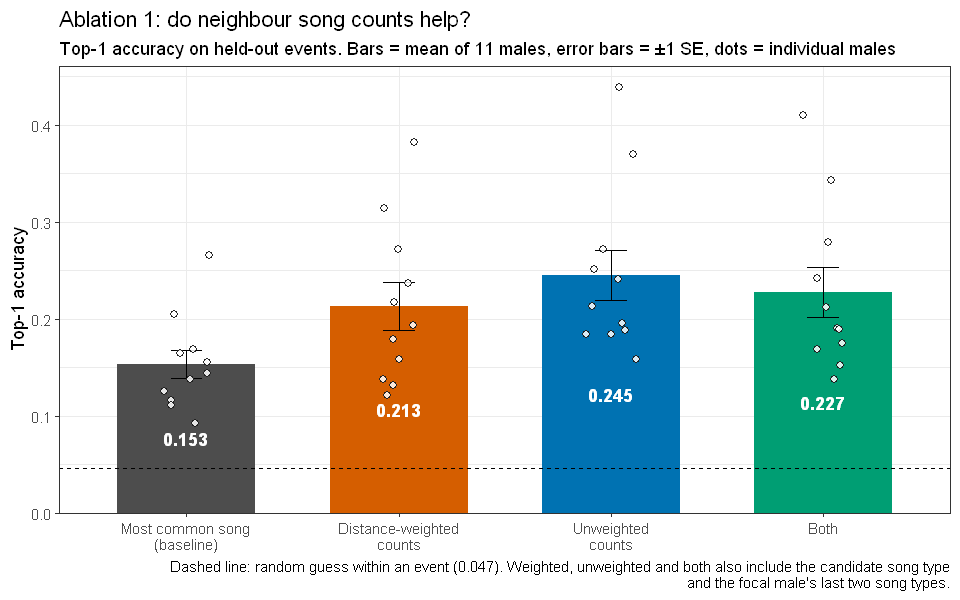

In [9]:
# ==============================================================================
# Ablation 1 bar chart: most-common-song baseline vs. unweighted / weighted / both
# Metric: top-1 accuracy on held-out test events, averaged across males
# Uses: ablation_results (from the cell above), male_train_data, male_test_data
# ==============================================================================

# ---- Settings ------------------------------------------------------------------
INCLUDE_OWN_HISTORY <- FALSE   # TRUE adds the own-history-only model (Ablation 1's "baseline") as an extra bar
options(repr.plot.width = 8, repr.plot.height = 5)   # only affects Jupyter/IRkernel

# ---- 1. Baseline: always predict the most common song type ---------------------
# The type that was the true match most often in a male's training events is predicted for
# every one of his test events (ties: lower song type number first). Training events only.
most_common_baseline <- function(train, test) {
    top_type <- train %>%
        filter(match_class == "match") %>%
        count(candidate_ust = as.character(candidate_ust)) %>%
        arrange(desc(n), as.numeric(candidate_ust)) %>%
        slice(1) %>%
        pull(candidate_ust)
    test %>%
        filter(match_class == "match") %>%
        summarise(accuracy = mean(as.character(candidate_ust) == top_type))
}
baseline_acc <- map2_dfr(male_train_data, male_test_data, most_common_baseline, .id = "focal_male")

# ---- 2. Combine with the ablation results -----------------------------------------
model_labels <- c(most_common = "Most common song\n(baseline)",
                  weighted    = "Distance-weighted\ncounts",
                  unweighted  = "Unweighted\ncounts",
                  both        = "Both")
if (INCLUDE_OWN_HISTORY) {
    model_labels <- c(model_labels[1], own_history = "Own history\nonly", model_labels[-1])
}
fill_cols <- c(most_common = "#4D4D4D", own_history = "#6E6E6E",
               weighted = "#D55E00", unweighted = "#0072B2", both = "#009E73")

plot_data <- bind_rows(
    baseline_acc %>% mutate(model = "most_common"),
    ablation_results %>% transmute(focal_male, accuracy,
                                   model = recode(as.character(feature_set), baseline = "own_history"))
) %>%
    filter(model %in% names(model_labels)) %>%
    mutate(model = factor(model, levels = names(model_labels), labels = unname(model_labels)))

summary_tbl <- plot_data %>%
    group_by(model) %>%
    summarise(n_males = n(), mean_acc = mean(accuracy),
              se = sd(accuracy) / sqrt(n()), .groups = "drop")
print(summary_tbl)

random_acc <- ablation_results %>% distinct(focal_male, .keep_all = TRUE) %>% pull(random_baseline) %>% mean()

# ---- 3. Plot -----------------------------------------------------------------------
p <- ggplot(summary_tbl, aes(x = model, y = mean_acc, fill = model)) +
    geom_col(width = 0.65) +
    geom_errorbar(aes(ymin = mean_acc - se, ymax = mean_acc + se), width = 0.15) +
    geom_hline(yintercept = random_acc, linetype = "dashed") +
    geom_point(data = plot_data, aes(x = model, y = accuracy), inherit.aes = FALSE,
               shape = 21, fill = "white", colour = "black", size = 2, alpha = 0.85,
               position = position_jitter(width = 0.12, height = 0, seed = 1)) +
    geom_text(aes(y = mean_acc / 2, label = sprintf("%.3f", mean_acc)),
              colour = "white", fontface = "bold") +
    scale_fill_manual(values = setNames(fill_cols[names(model_labels)], unname(model_labels)),
                      guide = "none") +
    scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.05))) +
    labs(title = "Ablation 1: do neighbour song counts help?",
         subtitle = sprintf("Top-1 accuracy on held-out events. Bars = mean of %d males, error bars = \u00b11 SE, dots = individual males",
                            n_distinct(plot_data$focal_male)),
         x = NULL, y = "Top-1 accuracy",
         caption = sprintf(paste0("Dashed line: random guess within an event (%.3f). ",
                                  "Weighted, unweighted and both also include the candidate song type\n",
                                  "and the focal male's last two song types."), random_acc)) +
    theme_bw()

print(p)

ggsave(file.path(RESULTS_DIR, paste0(MODEL_NAME, "_ablation1_barchart.png")),
       plot = p, width = 8, height = 5, units = "in", dpi = 300)